# Experiment 10: Low-Resource Neural Machine Translation (English → Assamese)

This notebook follows the Exp 10 brief using the English–Assamese parallel CSV dataset and an NLLB-200 encoder-decoder model. Run the cells from top to bottom in Google Colab (GPU runtime recommended).

**Input CSV requirement:** the uploaded file must contain `en` (English source) and `as` (Assamese target) columns. The notebook evaluates a pretrained baseline and a fine-tuned model on the same held-out test subset. Training/evaluation scores are produced only after the notebook is run with the actual dataset; no results are fabricated.


In [ ]:
!pip install -q pandas==2.2.3

In [ ]:
!pip -q install -U transformers datasets sentencepiece sacrebleu accelerate scikit-learn matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os

from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Please upload the English-Assamese training CSV file.")
file_name = csv_files[0]
print("Using dataset:", file_name)

Saving English-Assamese Training Data 2026.csv to English-Assamese Training Data 2026.csv
Using dataset: English-Assamese Training Data 2026.csv


In [ ]:
file_name = file_name if "file_name" in globals() else "English-Assamese Training Data 2026.csv"

df = pd.read_csv(file_name)
required_columns = {"en", "as"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_columns)}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (54000, 2)


,en,as
0,Similarly there is a great need for value addi...,ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱ...
1,Lemon tanga also has a good market for sorbet ...,নেমুটেঙাৰ চৰবত আচাৰ আদিৰো ভাল বজাৰ আছে ।
2,These crops are very much available in Assam b...,এই শস্যকেইবিধ অসমত যথেষ্ট হয় কিন্তু মূল্য সংযো...
3,A lot of money goes out of the state exchequer...,অসমলৈ বহু পৰিমাণৰ বীজ আমদানি কৰাৰ বাবে ৰাজ্যখন...
4,But many youth of the state can be established...,কিন্তু ধান সৰিয়হ মাটিমাহ নেমু কল বহুতো ফল ফুলৰ...


In [ ]:
print("Dataset Information:")
print("-" * 50)

df.info()

Dataset Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54000 entries, 0 to 53999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   en      54000 non-null  object
 1   as      54000 non-null  object
dtypes: object(2)
memory usage: 843.9+ KB


In [ ]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['en', 'as']


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
en    0
as    0
dtype: int64


In [ ]:
duplicates = df.duplicated().sum()

print("Number of duplicate sentence pairs:", duplicates)

Number of duplicate sentence pairs: 77


In [ ]:
# Remove missing values and normalize whitespace
df = df.dropna(subset=["en", "as"]).copy()
df["en"] = df["en"].astype(str).str.replace(r"\\s+", " ", regex=True).str.strip()
df["as"] = df["as"].astype(str).str.replace(r"\\s+", " ", regex=True).str.strip()

# Remove empty pairs and exact duplicate pairs
df = df[(df["en"] != "") & (df["as"] != "")]
df = df.drop_duplicates(subset=["en", "as"]).reset_index(drop=True)

if len(df) < 10:
    raise ValueError(
        f"Only {len(df)} usable sentence pairs remain. "
        "Please check the CSV and ensure it contains enough parallel data."
    )

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (53923, 2)


In [ ]:
for i in range(min(5, len(df))):
    print(f"Example {i + 1}")
    print("English:")
    print(df.iloc[i]["en"])
    print("\\nAssamese:")
    print(df.iloc[i]["as"])
    print("-" * 80)

Example 1
English:
Similarly there is a great need for value addition of soil .
\nAssamese:
ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱশ্যক আছে ।
--------------------------------------------------------------------------------
Example 2
English:
Lemon tanga also has a good market for sorbet pickles etc .
\nAssamese:
নেমুটেঙাৰ চৰবত আচাৰ আদিৰো ভাল বজাৰ আছে ।
--------------------------------------------------------------------------------
Example 3
English:
These crops are very much available in Assam but Assamese farmers have not been benefited due to lack of value addition .
\nAssamese:
এই শস্যকেইবিধ অসমত যথেষ্ট হয় কিন্তু মূল্য সংযোজনৰ অভাৱত অসমীয়া কৃষকসকল লাভৱান হ’ব পৰা নাই ।
--------------------------------------------------------------------------------
Example 4
English:
A lot of money goes out of the state exchequer to import a lot of seeds to Assam .
\nAssamese:
অসমলৈ বহু পৰিমাণৰ বীজ আমদানি কৰাৰ বাবে ৰাজ্যখনৰ ৰাজকোষৰ পৰা যথেষ্ট ধন বাহিৰলৈ যায় ।
---------------------------------

In [ ]:
df['english_word_count'] = df['en'].apply(lambda x: len(x.split()))
df['assamese_word_count'] = df['as'].apply(lambda x: len(x.split()))

df[['english_word_count', 'assamese_word_count']].describe()

,english_word_count,assamese_word_count
count,53923.000000,53923.000000
mean,19.141517,16.269718
std,7.546204,7.256413
min,2.000000,2.000000
25%,13.000000,11.000000
50%,19.000000,16.000000
75%,25.000000,21.000000
max,64.000000,79.000000


In [ ]:
print("Average English sentence length:",
      round(df['english_word_count'].mean(), 2))

print("Average Assamese sentence length:",
      round(df['assamese_word_count'].mean(), 2))

print("Maximum English sentence length:",
      df['english_word_count'].max())

print("Maximum Assamese sentence length:",
      df['assamese_word_count'].max())

Average English sentence length: 19.14
Average Assamese sentence length: 16.27
Maximum English sentence length: 64
Maximum Assamese sentence length: 79


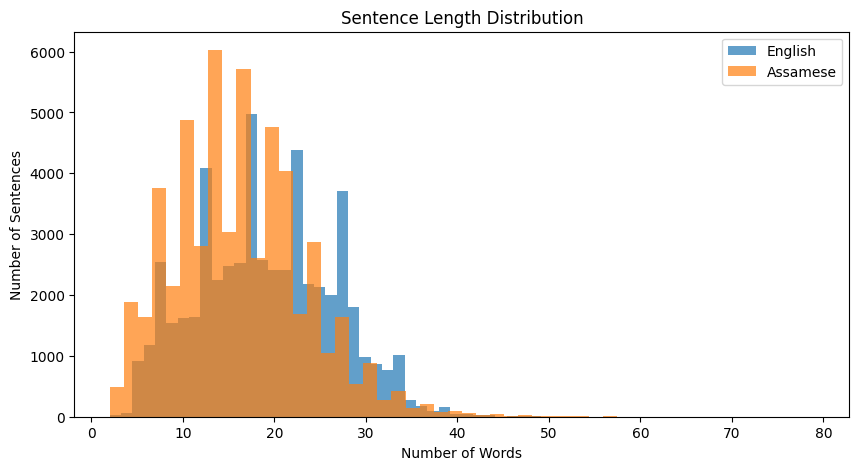

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df['english_word_count'], bins=50, alpha=0.7, label='English')
plt.hist(df['assamese_word_count'], bins=50, alpha=0.7, label='Assamese')

plt.xlabel("Number of Words")
plt.ylabel("Number of Sentences")
plt.title("Sentence Length Distribution")
plt.legend()

plt.show()

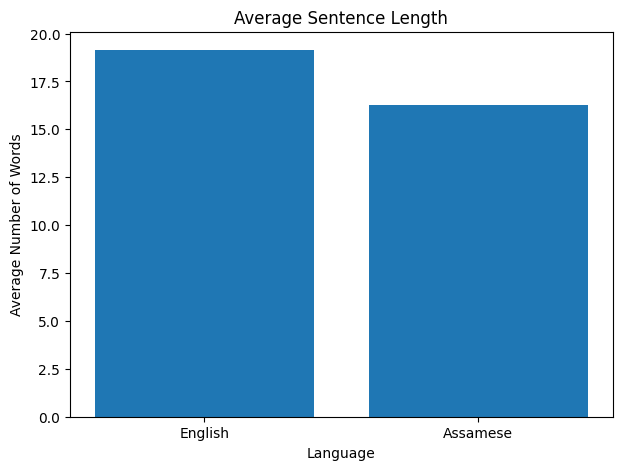

In [ ]:
languages = ['English', 'Assamese']

average_lengths = [
    df['english_word_count'].mean(),
    df['assamese_word_count'].mean()
]

plt.figure(figsize=(7, 5))

plt.bar(languages, average_lengths)

plt.xlabel("Language")
plt.ylabel("Average Number of Words")
plt.title("Average Sentence Length")

plt.show()

In [ ]:
long_sentences = df[
    (df['english_word_count'] > 100) |
    (df['assamese_word_count'] > 100)
]

print("Sentence pairs longer than 100 words:")
print(len(long_sentences))

Sentence pairs longer than 100 words:
0


In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Total sentence pairs:", len(df))
print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Testing pairs:", len(test_df))

Total sentence pairs: 53923
Training pairs: 43138
Validation pairs: 5392
Testing pairs: 5393


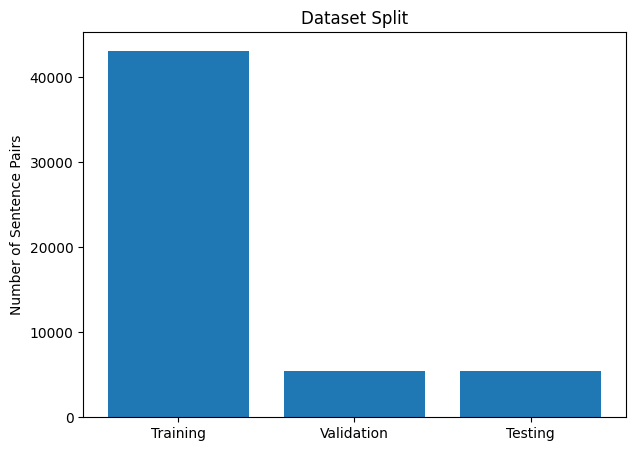

In [ ]:
split_names = ['Training', 'Validation', 'Testing']

split_sizes = [
    len(train_df),
    len(val_df),
    len(test_df)
]

plt.figure(figsize=(7, 5))

plt.bar(split_names, split_sizes)

plt.ylabel("Number of Sentence Pairs")
plt.title("Dataset Split")

plt.show()

In [ ]:
train_df[['en', 'as']].to_csv(
    "train_en_as.csv",
    index=False
)

val_df[['en', 'as']].to_csv(
    "validation_en_as.csv",
    index=False
)

test_df[['en', 'as']].to_csv(
    "test_en_as.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [ ]:
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(f"Total cleaned sentence pairs : {len(df)}")
print(f"Training sentence pairs      : {len(train_df)}")
print(f"Validation sentence pairs    : {len(val_df)}")
print(f"Testing sentence pairs       : {len(test_df)}")

print()

print(
    f"Average English length       : "
    f"{df['english_word_count'].mean():.2f} words"
)

print(
    f"Average Assamese length      : "
    f"{df['assamese_word_count'].mean():.2f} words"
)

print("=" * 60)

DATASET SUMMARY
Total cleaned sentence pairs : 53923
Training sentence pairs      : 43138
Validation sentence pairs    : 5392
Testing sentence pairs       : 5393

Average English length       : 19.14 words
Average Assamese length      : 16.27 words


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("GPU available:", torch.cuda.is_available())
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
Using device: cuda
GPU: Tesla T4


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq
)

print("Transformer libraries imported successfully!")

Transformer libraries imported successfully!


In [ ]:
MODEL_NAME = "facebook/nllb-200-distilled-600M"

SOURCE_LANG = "eng_Latn"
TARGET_LANG = "asm_Beng"

print("Model:", MODEL_NAME)
print("Source language:", SOURCE_LANG)
print("Target language:", TARGET_LANG)

Model: facebook/nllb-200-distilled-600M
Source language: eng_Latn
Target language: asm_Beng


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    src_lang=SOURCE_LANG,
    tgt_lang=TARGET_LANG
)

print("Tokenizer loaded successfully!")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [ ]:
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
model = model.to(device)

print("NLLB model loaded successfully!")
print("Device:", next(model.parameters()).device)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

NLLB model loaded successfully!
Device: cuda:0


In [ ]:
def translate_english_to_assamese(text):
    model.eval()
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        generated_tokens = model.generate(
            **inputs,
            forced_bos_token_id=tokenizer.convert_tokens_to_ids(TARGET_LANG),
            max_length=128,
            num_beams=4
        )

    return tokenizer.batch_decode(
        generated_tokens,
        skip_special_tokens=True
    )[0]

In [ ]:
english_sentence = "India is a country with many languages and cultures."

assamese_translation = translate_english_to_assamese(
    english_sentence
)

print("English:")
print(english_sentence)

print("\nAssamese Translation:")
print(assamese_translation)

English:
India is a country with many languages and cultures.

Assamese Translation:
ভাৰতবর্ষ বহু ভাষা আৰু সংস্কৃতিৰ দেশ।


In [ ]:
import pandas as pd

# Reload the processed datasets
train_df = pd.read_csv("train_en_as.csv")
val_df = pd.read_csv("validation_en_as.csv")
test_df = pd.read_csv("test_en_as.csv")

print("Datasets reloaded successfully!")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Datasets reloaded successfully!
Training: (43138, 2)
Validation: (5392, 2)
Testing: (5393, 2)


In [ ]:
sample = test_df.iloc[0]

english_text = sample["en"]
reference_assamese = sample["as"]

predicted_assamese = translate_english_to_assamese(
    english_text
)

print("ENGLISH:")
print(english_text)

print("\nREFERENCE ASSAMESE:")
print(reference_assamese)

print("\nNLLB PREDICTION:")
print(predicted_assamese)

ENGLISH:
For at that time day by day there came to David to help him , until it was a great host , like the host of God .

REFERENCE ASSAMESE:
দিনে দিনে , দায়ূদক সহায় কৰিবৰ বাবে লোকসকল আহি আছিল , যেতিয়ালৈকে তাত ঈশ্বৰৰ সৈন্যদলৰ দৰে এটা মহাসৈন্যদল গঠন নহ’ল ।

NLLB PREDICTION:
কিয়নো সেই সময়ত প্ৰতিদিনে দায়ুদৰ ওচৰলৈ তেওঁৰ সহায়ৰ বাবে অহা লোকসকল আছিল; আৰু ঈশ্বৰৰ সৈন্যৰ নিচিনা অনেক সৈন্য আছিল ।


In [ ]:
for i in range(min(5, len(test_df))):
    sample = test_df.iloc[i]
    english = sample["en"]
    reference = sample["as"]
    prediction = translate_english_to_assamese(english)

    print("=" * 100)
    print(f"EXAMPLE {i + 1}")
    print("\\nEnglish:")
    print(english)
    print("\\nReference Assamese:")
    print(reference)
    print("\\nNLLB Prediction:")
    print(prediction)
    print()

EXAMPLE 1
\nEnglish:
For at that time day by day there came to David to help him , until it was a great host , like the host of God .
\nReference Assamese:
দিনে দিনে , দায়ূদক সহায় কৰিবৰ বাবে লোকসকল আহি আছিল , যেতিয়ালৈকে তাত ঈশ্বৰৰ সৈন্যদলৰ দৰে এটা মহাসৈন্যদল গঠন নহ’ল ।
\nNLLB Prediction:
কিয়নো সেই সময়ত প্ৰতিদিনে দায়ুদৰ ওচৰলৈ তেওঁৰ সহায়ৰ বাবে অহা লোকসকল আছিল; আৰু ঈশ্বৰৰ সৈন্যৰ নিচিনা অনেক সৈন্য আছিল ।

EXAMPLE 2
\nEnglish:
( James 4 : 8 ) True , he is our Sovereign Lord , but he is also our Creator and Father .
\nReference Assamese:
( যাকোব ৪ : ৮ ) প্ৰকৃততে তেওঁৱেই হৈছে আমাৰ সৰ্ব্বশক্তিমান ঈশ্বৰ , তদুপৰি তেওঁ আমাৰ সৃষ্টিকৰ্ত্তা আৰু পিতৃও ।
\nNLLB Prediction:
(যাকোব ৪ঃ৮) যদিও তেওঁ আমাৰ সাৰ্বভৌম প্ৰভু , তেৱেঁই আমাৰ সৃষ্টিকৰ্তা আৰু পিতৃও ।

EXAMPLE 3
\nEnglish:
And to godliness brotherly kindness ; and to brotherly kindness charity .
\nReference Assamese:
যি জনৰ এই সকলো গুণ নাই , তেওঁ ওচৰতহে দেখে ; আচলতে তেওঁ অন্ধ । তেওঁক যে পূৰ্বৰ পাপ সমূহৰ পৰা শুচি কৰা হৈছে , সেই বিষয় তেওঁ পাহৰি 

In [ ]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[['en', 'as']].reset_index(drop=True)
)

val_dataset = Dataset.from_pandas(
    val_df[['en', 'as']].reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df[['en', 'as']].reset_index(drop=True)
)

print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['en', 'as'],
    num_rows: 43138
})
Dataset({
    features: ['en', 'as'],
    num_rows: 5392
})
Dataset({
    features: ['en', 'as'],
    num_rows: 5393
})


In [ ]:
MAX_LENGTH = 128

print("Maximum token length:", MAX_LENGTH)

Maximum token length: 128


In [ ]:
def preprocess_function(examples):

    model_inputs = tokenizer(
        examples["en"],
        max_length=MAX_LENGTH,
        truncation=True
    )

    labels = tokenizer(
        text_target=examples["as"],
        max_length=MAX_LENGTH,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]

    return model_inputs

In [ ]:
tokenized_train = train_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=train_dataset.column_names
)

print(tokenized_train)

Map:   0%|          | 0/43138 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 43138
})


In [ ]:
tokenized_val = val_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=val_dataset.column_names
)

print(tokenized_val)

Map:   0%|          | 0/5392 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 5392
})


In [ ]:
print("Original English:")
print(train_df.iloc[0]["en"])

print("\nToken IDs:")
print(tokenized_train[0]["input_ids"])

print("\nDecoded:")
print(
    tokenizer.decode(
        tokenized_train[0]["input_ids"],
        skip_special_tokens=False
    )
)

Original English:
And the days of Terah were two hundred and five years and Terah died in Haran .

Token IDs:
[256047, 3140, 349, 26214, 452, 109, 21305, 8444, 9872, 99296, 540, 54369, 12607, 540, 109, 21305, 76627, 108, 234686, 81, 2]

Decoded:
eng_Latn And the days of Terah were two hundred and five years and Terah died in Haran .</s>


In [ ]:
pilot_train = tokenized_train.select(
    range(min(10000, len(tokenized_train)))
)

pilot_val = tokenized_val.select(
    range(min(1000, len(tokenized_val)))
)

print("Pilot training examples:", len(pilot_train))
print("Pilot validation examples:", len(pilot_val))

Pilot training examples: 10000
Pilot validation examples: 1000


In [ ]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

print("Data collator created successfully!")

Data collator created successfully!


In [ ]:
model.config.use_cache = False

model.gradient_checkpointing_enable()

print("Gradient checkpointing enabled!")

Gradient checkpointing enabled!


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


In [ ]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="./nllb_assamese_pilot",
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=(device.type == "cuda"),
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    predict_with_generate=False,
    report_to="none"
)
print("Training configuration created!")

Training configuration created!


In [ ]:
from transformers import Seq2SeqTrainer

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,

    train_dataset=pilot_train,
    eval_dataset=pilot_val,

    processing_class=tokenizer,
    data_collator=data_collator
)

print("Trainer created successfully!")

Trainer created successfully!


In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU Available: True
GPU: Tesla T4


In [ ]:
!nvidia-smi

Tue Nov 24 19:16:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P0             26W /   70W |    2547MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss
1,16.046538,1.882791


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
print("Training completed!")

print("\nTraining metrics:")
print(train_result.metrics)

Training completed!

Training metrics:
{'train_runtime': 1379.649, 'train_samples_per_second': 7.248, 'train_steps_per_second': 0.453, 'total_flos': 639448232165376.0, 'train_loss': 16.609011767578124, 'epoch': 1.0}


In [ ]:
SAVE_PATH = "./english_assamese_nllb"

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Fine-tuned model saved to:", SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned model saved to: ./english_assamese_nllb


In [ ]:
model.config.use_cache = True
model.eval()

print("Model switched to evaluation mode.")

Model switched to evaluation mode.


In [ ]:
def translate_finetuned(text):
    model.eval()
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        generated = model.generate(
            **inputs,
            forced_bos_token_id=tokenizer.convert_tokens_to_ids(TARGET_LANG),
            max_length=128,
            num_beams=4
        )

    return tokenizer.batch_decode(
        generated,
        skip_special_tokens=True
    )[0]

In [ ]:
sentence = "India is a country with many languages and cultures."

translation = translate_finetuned(sentence)

print("English:")
print(sentence)

print("\nFine-tuned Assamese Translation:")
print(translation)

English:
India is a country with many languages and cultures.

Fine-tuned Assamese Translation:
ভাৰতবৰ্ষ বহু ভাষা আৰু সংস্কৃতিৰ দেশ ।


In [ ]:
sample = test_df.iloc[0]

english = sample["en"]
reference = sample["as"]

prediction = translate_finetuned(english)

print("=" * 80)

print("ENGLISH:")
print(english)

print("\nREFERENCE:")
print(reference)

print("\nFINE-TUNED NLLB:")
print(prediction)

print("=" * 80)

ENGLISH:
For at that time day by day there came to David to help him , until it was a great host , like the host of God .

REFERENCE:
দিনে দিনে , দায়ূদক সহায় কৰিবৰ বাবে লোকসকল আহি আছিল , যেতিয়ালৈকে তাত ঈশ্বৰৰ সৈন্যদলৰ দৰে এটা মহাসৈন্যদল গঠন নহ’ল ।

FINE-TUNED NLLB:
কিয়নো সেই সময়ত প্ৰতিদিনে দায়ূদৰ ওচৰলৈ তেওঁৰ সহায় কৰিবলৈ অহা লোকসকল আছিল ; আৰু ঈশ্বৰৰ সৈন্যৰ নিচিনা এটা বৃহৎ সৈন্যদল আছিল ।


In [ ]:
import sacrebleu
import time

print("SacreBLEU version:", sacrebleu.__version__)

SacreBLEU version: 2.6.0


In [ ]:
EVAL_SIZE = min(500, len(test_df))
if EVAL_SIZE == 0:
    raise ValueError("The test dataset is empty. Check the dataset split.")

eval_df = test_df.sample(
    n=EVAL_SIZE,
    random_state=42
).reset_index(drop=True)

print("Number of evaluation sentences:", len(eval_df))

Number of evaluation sentences: 500


In [ ]:
def translate_batch(texts, batch_size=4):
    predictions = []
    model.eval()

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128
        ).to(device)

        with torch.no_grad():
            generated = model.generate(
                **inputs,
                forced_bos_token_id=tokenizer.convert_tokens_to_ids(TARGET_LANG),
                max_length=128,
                num_beams=4
            )

        predictions.extend(
            tokenizer.batch_decode(generated, skip_special_tokens=True)
        )
        print(f"Translated {min(i + batch_size, len(texts))}/{len(texts)}")

    return predictions

In [ ]:
english_sentences = eval_df["en"].tolist()
references = eval_df["as"].tolist()

start_time = time.time()

finetuned_predictions = translate_batch(
    english_sentences
)

end_time = time.time()

print("\nTranslation completed!")
print("Predictions:", len(finetuned_predictions))
print(
    "Time taken:",
    round((end_time - start_time) / 60, 2),
    "minutes"
)

Translated 4/500
Translated 8/500
Translated 12/500
Translated 16/500
Translated 20/500
Translated 24/500
Translated 28/500
Translated 32/500
Translated 36/500
Translated 40/500
Translated 44/500
Translated 48/500
Translated 52/500
Translated 56/500
Translated 60/500
Translated 64/500
Translated 68/500
Translated 72/500
Translated 76/500
Translated 80/500
Translated 84/500
Translated 88/500
Translated 92/500
Translated 96/500
Translated 100/500
Translated 104/500
Translated 108/500
Translated 112/500
Translated 116/500
Translated 120/500
Translated 124/500
Translated 128/500
Translated 132/500
Translated 136/500
Translated 140/500
Translated 144/500
Translated 148/500
Translated 152/500
Translated 156/500
Translated 160/500
Translated 164/500
Translated 168/500
Translated 172/500
Translated 176/500
Translated 180/500
Translated 184/500
Translated 188/500
Translated 192/500
Translated 196/500
Translated 200/500
Translated 204/500
Translated 208/500
Translated 212/500
Translated 216/500


In [ ]:
bleu = sacrebleu.corpus_bleu(
    finetuned_predictions,
    [references]
)

print("Fine-tuned NLLB BLEU Score:")
print(round(bleu.score, 2))

Fine-tuned NLLB BLEU Score:
11.34


In [ ]:
chrf = sacrebleu.corpus_chrf(
    finetuned_predictions,
    [references]
)

print("Fine-tuned NLLB chrF Score:")
print(round(chrf.score, 2))

Fine-tuned NLLB chrF Score:
38.54


In [ ]:
finetuned_bleu = bleu.score
finetuned_chrf = chrf.score

print("=" * 50)
print("FINE-TUNED NLLB RESULTS")
print("=" * 50)

print(f"BLEU Score : {finetuned_bleu:.2f}")
print(f"chrF Score : {finetuned_chrf:.2f}")

print("=" * 50)

FINE-TUNED NLLB RESULTS
BLEU Score : 11.34
chrF Score : 38.54


In [ ]:
results_df = pd.DataFrame({
    "English": english_sentences,
    "Reference Assamese": references,
    "Predicted Assamese": finetuned_predictions
})

results_df.head(10)

,English,Reference Assamese,Predicted Assamese
0,But I have trusted in thy mercy ; my heart sha...,কিন্তু মই তোমাৰ দৃঢ় প্রেমত ভাৰসা কৰিছোঁ ; তুম...,কিন্তু মই তোমাৰ দয়াত ভাৰসা কৰিলোঁ ; তোমাৰ পৰি...
1,"Thou shalt not revile the gods , nor curse the...","তোমালোকৰ ঈশ্বৰ যি মই , মোক নিন্দা নকৰিবা , নাই...","তুমি দেৱতাবোৰক নিন্দা নকৰিবা , আৰু তোমাৰ লোকসক..."
2,A political or territorial unit ruled by a sov...,"একনায়কত্ব থকা কোনো এক ৰাজনৈতিক পৰিসৰ , য’ত ৰজা...",ৰাজা বা ৰাণী হব পৰা ৰাজনীতিক বা আঞ্চলিক গোট ।
3,It is not uncommon for someone to fall into th...,( খ ) জন্মৰ আগতেই যীচুয়ে কেনেকৈ সন্মান লাভ কৰ...,কোনোবাই নদীত পৰি বা যাত্ৰাৰ সময়ত বনৰীয়া গছজো...
4,And David reigned over all Israel ; and David ...,এইদৰে গোটেই ইস্ৰায়েলৰ ওপৰত ৰাজত্ব কৰি দায়ূদে...,দায়ূদে গোটেই ইস্ৰায়েলৰ ওপৰত ৰাজত্ব কৰিছিল ; ...
5,"Son of man , hath not the house of Israel , th...","হে মনুষ্য সন্তান , ‘তুমি কি কৰিছা ?’ এই বুলি ব...","হে মনুষ্য সন্তান , বিদ্ৰোহী ইস্ৰায়েল বংশই তোম..."
6,My chest trembled when I saw Mrs . Ugramurti .,শ্ৰীমতীৰ উগ্ৰমূৰ্তি দেখি মোৰ বুকু কঁপি গল ।,শ্ৰীমতী উগ্ৰামুৰ্তীক দেখি মোৰ বুকুৱে কম্পিত হল ।
7,Joint Interpretative Declarations/Statements i...,এই সহযোগিতা চুক্তিখনৰ সম্পর্কত দুয়োদেশৰ ফালৰ ...,বিনিয়োগ চুক্তি প্ৰণালীক শক্তিশালী কৰাত সাধাৰণ...
8,"( Proverbs 27 : 11 ) With good reason , then ,...",( হিতোপদেশ ২৭ : ১১ ) গতিকে আঁহক আমি ইয়োবৰ দৰে...,( হিতোপদেশ ২৭ : ১১ ) সেয়েহে আমি ইয়োবৰ দৰে দৃ...
9,Team India beat Team India for the first time ...,বাংলাদেশৰ চমক টী২০ত প্ৰথমবাৰৰ বাবে পৰাস্ত কৰিল...,বাংলাদেশৰ ছাৰপ্ৰাইজ টি-২০ত প্ৰথমবাৰৰ বাবে টীম ...


In [ ]:
results_df.to_csv(
    "finetuned_nllb_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [ ]:
import gc
import torch

# Move the fine-tuned model off GPU before loading the baseline to reduce peak memory.
model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print("Fine-tuned model moved to CPU; GPU cache cleared.")

Fine-tuned model moved to CPU; GPU cache cleared.


In [ ]:
from transformers import AutoModelForSeq2SeqLM

baseline_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
baseline_model.eval()

print("Original pretrained NLLB loaded!")
print("Device:", next(baseline_model.parameters()).device)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Original pretrained NLLB loaded!
Device: cuda:0


In [ ]:
def translate_baseline_batch(texts, batch_size=4):
    predictions = []
    baseline_model.eval()

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128
        ).to(device)

        with torch.no_grad():
            generated = baseline_model.generate(
                **inputs,
                forced_bos_token_id=tokenizer.convert_tokens_to_ids(TARGET_LANG),
                max_length=128,
                num_beams=4
            )

        predictions.extend(
            tokenizer.batch_decode(generated, skip_special_tokens=True)
        )
        print(f"Translated {min(i + batch_size, len(texts))}/{len(texts)}")

    return predictions

In [ ]:
start_time = time.time()

baseline_predictions = translate_baseline_batch(
    english_sentences
)

end_time = time.time()

print("\nBaseline translation completed!")

print(
    "Time taken:",
    round((end_time - start_time) / 60, 2),
    "minutes"
)

Translated 4/500
Translated 8/500
Translated 12/500
Translated 16/500
Translated 20/500
Translated 24/500
Translated 28/500
Translated 32/500
Translated 36/500
Translated 40/500
Translated 44/500
Translated 48/500
Translated 52/500
Translated 56/500
Translated 60/500
Translated 64/500
Translated 68/500
Translated 72/500
Translated 76/500
Translated 80/500
Translated 84/500
Translated 88/500
Translated 92/500
Translated 96/500
Translated 100/500
Translated 104/500
Translated 108/500
Translated 112/500
Translated 116/500
Translated 120/500
Translated 124/500
Translated 128/500
Translated 132/500
Translated 136/500
Translated 140/500
Translated 144/500
Translated 148/500
Translated 152/500
Translated 156/500
Translated 160/500
Translated 164/500
Translated 168/500
Translated 172/500
Translated 176/500
Translated 180/500
Translated 184/500
Translated 188/500
Translated 192/500
Translated 196/500
Translated 200/500
Translated 204/500
Translated 208/500
Translated 212/500
Translated 216/500


In [ ]:
baseline_bleu_result = sacrebleu.corpus_bleu(
    baseline_predictions,
    [references]
)

baseline_bleu = baseline_bleu_result.score

print(
    "Original NLLB BLEU Score:",
    round(baseline_bleu, 2)
)

Original NLLB BLEU Score: 8.94


In [ ]:
baseline_chrf_result = sacrebleu.corpus_chrf(
    baseline_predictions,
    [references]
)

baseline_chrf = baseline_chrf_result.score

print(
    "Original NLLB chrF Score:",
    round(baseline_chrf, 2)
)

Original NLLB chrF Score: 37.17


In [ ]:
comparison_df = pd.DataFrame({
    "Model": [
        "Pretrained NLLB-200",
        "Fine-tuned NLLB-200"
    ],

    "BLEU": [
        baseline_bleu,
        finetuned_bleu
    ],

    "chrF": [
        baseline_chrf,
        finetuned_chrf
    ]
})

comparison_df["BLEU"] = comparison_df["BLEU"].round(2)
comparison_df["chrF"] = comparison_df["chrF"].round(2)

comparison_df

,Model,BLEU,chrF
0,Pretrained NLLB-200,8.94,37.17
1,Fine-tuned NLLB-200,11.34,38.54


In [ ]:
bleu_improvement = finetuned_bleu - baseline_bleu
chrf_improvement = finetuned_chrf - baseline_chrf

print("=" * 55)
print("IMPROVEMENT AFTER FINE-TUNING")
print("=" * 55)

print(
    f"BLEU improvement : {bleu_improvement:+.2f}"
)

print(
    f"chrF improvement : {chrf_improvement:+.2f}"
)

print("=" * 55)

IMPROVEMENT AFTER FINE-TUNING
BLEU improvement : +2.40
chrF improvement : +1.38


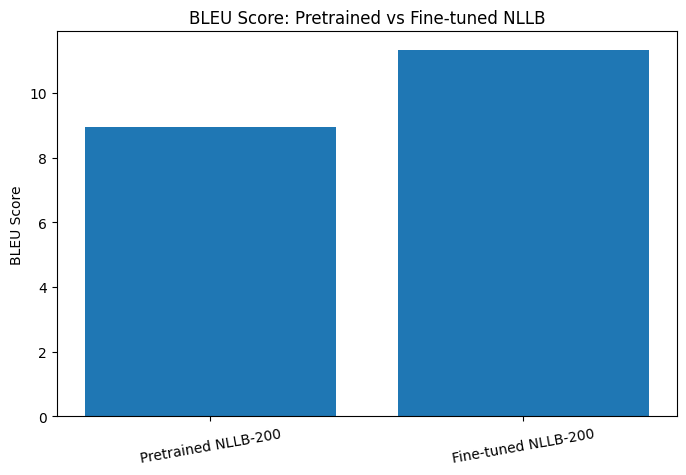

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["BLEU"]
)

plt.ylabel("BLEU Score")
plt.title("BLEU Score: Pretrained vs Fine-tuned NLLB")

plt.xticks(rotation=10)

plt.show()

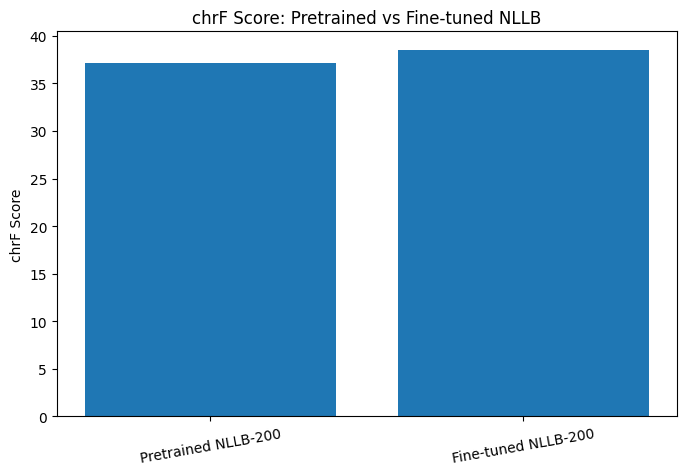

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["chrF"]
)

plt.ylabel("chrF Score")
plt.title("chrF Score: Pretrained vs Fine-tuned NLLB")

plt.xticks(rotation=10)

plt.show()

In [ ]:
print("Evaluation comparison uses the same held-out test examples for both models.")
print("The fine-tuned model was trained on the pilot subset defined above.")

Evaluation comparison uses the same held-out test examples for both models.
The fine-tuned model was trained on the pilot subset defined above.


In [ ]:
import gc
import torch

baseline_model.cpu()
del baseline_model

torch.cuda.empty_cache()
gc.collect()

print("GPU memory cleared.")


GPU memory cleared.
